# CONUS annual temperature baseline update

Rewrite existing Wobus output files for the requested Neumann et al. (2021) public-infrastructure application. Retain absolute annual temperatures; remove both 2001–2020 baseline/warming variables; calculate a 1986–2005 baseline and annual warming relative to it. Paths and filenames stay unchanged. No raw climate files or boundary shapefiles are needed.

Run cells from top to bottom on Keeling. Each file must contain all years 1985–2094 and finite annual temperatures, with Celsius units. The baseline is an equal-weight mean of 20 annual values. Files that fail validation are reported and left unchanged. Replacement occurs only after a temporary NetCDF has been validated. The original file is replaced, so this operation does not retain a backup.

In [11]:
from pathlib import Path
from datetime import datetime, timezone
import os
import tempfile
import numpy as np
import xarray as xr
from tqdm.auto import tqdm

OUTPUT_ROOT = Path('/data/keeling/a/tahsina2/b/Climate_Impact/Data/LOCA2_Illinois/Wobus et al. (2021)')
BASELINE_START, BASELINE_END = 1986, 2005
OVERWRITE = True
OLD_VARIABLES = ('baseline_2001_2020_temperature', 'conus_warming_relative_to_2001_2020')
BASELINE_NAME = 'baseline_1986_2005_temperature'
WARMING_NAME = 'conus_warming_relative_to_1986_2005'
TEMPERATURE_NAME = 'conus_annual_mean_temperature'

In [12]:
files = sorted(OUTPUT_ROOT.glob('*.nc'))
if not files:
    raise FileNotFoundError(f'No existing NetCDF files found in {OUTPUT_ROOT}')
print('Folder:', OUTPUT_ROOT)
print('Existing files to rewrite:', len(files))
print('Baseline:', BASELINE_START, 'through', BASELINE_END)

Folder: /data/keeling/a/tahsina2/b/Climate_Impact/Data/LOCA2_Illinois/Wobus et al. (2021)
Existing files to rewrite: 156
Baseline: 1986 through 2005


In [13]:
def update_baseline(source):
    if TEMPERATURE_NAME not in source:
        raise ValueError(f'Missing {TEMPERATURE_NAME}')
    temperature = source[TEMPERATURE_NAME].copy(deep=True)

    # Handles the confirmed case of Kelvin values mislabeled as Celsius.
    median_temperature = float(temperature.median(skipna=True).item())
    
    if median_temperature > 150.0:
        temperature = temperature - 273.15
        temperature.attrs = dict(source[TEMPERATURE_NAME].attrs)
        temperature.attrs["units"] = "degree_Celsius"
        temperature.attrs["unit_correction"] = (
            "Subtracted 273.15 from Kelvin values previously labeled Celsius"
        )
        print("Converted absolute temperature from Kelvin to Celsius.")
    else:
        print("Absolute temperature already appears to be Celsius; no conversion.")




    
    if temperature.dims != ('calendar_year',):
        raise ValueError(f'Unexpected temperature dimensions: {temperature.dims}')
    years = source.calendar_year.values
    if not np.array_equal(years, np.arange(1985, 2095)):
        raise ValueError('Expected unique, ordered calendar years 1985–2094')
    units = str(temperature.attrs.get('units', source.attrs.get('absolute_temperature_units', '')))
    normalized = units.strip().lower().replace('_', '').replace(' ', '')
    if normalized not in {'degreecelsius', 'degreescelsius', 'degc', 'celsius', '°c', 'c'}:
        raise ValueError(f'Expected Celsius absolute temperatures; found units {units!r}')
    if not np.isfinite(temperature.values).all():
        raise ValueError('Annual temperature contains missing or nonfinite values')
    baseline_values = temperature.sel(calendar_year=np.arange(BASELINE_START, BASELINE_END + 1))
    baseline = baseline_values.mean('calendar_year', skipna=False)
    result = source.drop_vars([v for v in OLD_VARIABLES if v in source]).copy(deep=True)
    result[TEMPERATURE_NAME] = temperature
    result.attrs["absolute_temperature_units"] = "degrees Celsius"
    result[BASELINE_NAME] = baseline
    result[BASELINE_NAME].attrs = {
        'units': 'degree_Celsius',
        'long_name': 'CONUS annual temperature averaged over 1986–2005',
        'baseline_period': '1986-2005',
        'calculation': 'arithmetic mean of 20 annual temperatures; equal weight per year',
    }
    result[WARMING_NAME] = temperature - baseline
    result[WARMING_NAME].attrs = {
        'units': 'degree_Celsius',
        'long_name': 'Annual CONUS mean temperature change relative to 1986–2005',
        'baseline_period': '1986-2005',
        'calculation': f'{TEMPERATURE_NAME} minus {BASELINE_NAME}',
    }
    result.attrs.update(
        baseline_period='1986-2005', baseline_start_year=1986, baseline_end_year=2005,
        baseline_method='equal-weight arithmetic mean of 20 annual temperatures',
        baseline_experiment='historical simulation',
        application='Neumann et al. (2021) public infrastructure climate input',
        scenarios='ssp245 and ssp370',
    )
    # Keep the original paper/model/member/scenario provenance.
    stamp = datetime.now(timezone.utc).isoformat()
    previous = str(result.attrs.get('history', '')).strip()
    entry = f'{stamp}: replaced 2001–2020 baseline and warming with 1986–2005 baseline and warming; absolute temperature preserved.'
    result.attrs['history'] = (previous + '\n' + entry).strip()
    return result


def rewrite_existing_file(path):
    if not OVERWRITE:
        return 'skipped'
    with xr.open_dataset(path, decode_timedelta=False) as opened:
        source = opened.load()
    result = update_baseline(source)
    temporary = None
    try:
        with tempfile.NamedTemporaryFile(dir=path.parent, prefix=f'.{path.stem}_', suffix='.tmp', delete=False) as handle:
            temporary = Path(handle.name)
        # Clear backend-specific encodings before saving the rewritten dataset.
        for variable in result.variables:
            result[variable].encoding = {}
        encoding = {
            name: {'zlib': True, 'complevel': 4, 'shuffle': True}
            for name in result.data_vars if result[name].ndim > 0
        }
        result.to_netcdf(temporary, engine='netcdf4', encoding=encoding)
        with xr.open_dataset(temporary, decode_timedelta=False) as verified:
            verified.load()
            if any(name in verified for name in OLD_VARIABLES):
                raise ValueError('Old baseline variables remain')
            for name in source.variables:
                if name not in OLD_VARIABLES and name not in (BASELINE_NAME, WARMING_NAME):
                    xr.testing.assert_identical(result[name], verified[name])
            xr.testing.assert_allclose(verified[BASELINE_NAME], result[BASELINE_NAME])
            xr.testing.assert_allclose(verified[WARMING_NAME], result[WARMING_NAME])
            mean_anomaly = verified[WARMING_NAME].sel(calendar_year=slice(1986, 2005)).mean().item()
            if not np.isclose(mean_anomaly, 0.0, atol=1e-10):
                raise ValueError('Mean baseline-period anomaly is not zero')
        os.chmod(temporary, path.stat().st_mode & 0o777)
        os.replace(temporary, path)
        return 'rewritten'
    finally:
        if temporary is not None and temporary.exists():
            temporary.unlink()
        source.close()
        result.close()

In [14]:
rewritten = skipped = 0
failures = []
for path in tqdm(files, desc='Rebase existing CONUS outputs', unit='file'):
    try:
        status = rewrite_existing_file(path)
        if status == 'rewritten':
            rewritten += 1
            print('REWROTE:', path.name)
        else:
            skipped += 1
    except Exception as exc:
        failures.append((path.name, f'{type(exc).__name__}: {exc}'))
        print('FAILED, original retained:', path.name, failures[-1][1])
print(f'Rewritten={rewritten}; skipped={skipped}; failed={len(failures)}')
if failures:
    print('Resolve failed files before treating the folder as fully updated.')

Rebase existing CONUS outputs:   0%|          | 0/156 [00:00<?, ?file/s]

Converted absolute temperature from Kelvin to Celsius.
REWROTE: Wobus_et_al_2021__ACCESS-CM2_r1i1p1f1_ssp245.nc
Converted absolute temperature from Kelvin to Celsius.
REWROTE: Wobus_et_al_2021__ACCESS-CM2_r1i1p1f1_ssp370.nc
Converted absolute temperature from Kelvin to Celsius.
REWROTE: Wobus_et_al_2021__ACCESS-CM2_r2i1p1f1_ssp245.nc
Converted absolute temperature from Kelvin to Celsius.
REWROTE: Wobus_et_al_2021__ACCESS-CM2_r2i1p1f1_ssp370.nc
Converted absolute temperature from Kelvin to Celsius.
REWROTE: Wobus_et_al_2021__ACCESS-CM2_r3i1p1f1_ssp245.nc
Converted absolute temperature from Kelvin to Celsius.
REWROTE: Wobus_et_al_2021__ACCESS-CM2_r3i1p1f1_ssp370.nc
Converted absolute temperature from Kelvin to Celsius.
REWROTE: Wobus_et_al_2021__ACCESS-ESM1-5_r1i1p1f1_ssp245.nc
Converted absolute temperature from Kelvin to Celsius.
REWROTE: Wobus_et_al_2021__ACCESS-ESM1-5_r1i1p1f1_ssp370.nc
Converted absolute temperature from Kelvin to Celsius.
REWROTE: Wobus_et_al_2021__ACCESS-ESM1-5_r2

In [15]:
with xr.open_dataset(files[0], decode_timedelta=False) as example:
    display(example)
    if BASELINE_NAME in example:
        print('1986–2005 baseline (°C):', example[BASELINE_NAME].item())
        

<xarray.Dataset> Size: 3kB
Dimensions:                              (calendar_year: 110)
Coordinates:
  * calendar_year                        (calendar_year) int64 880B 1985 ... ...
Data variables:
    conus_annual_mean_temperature        (calendar_year) float64 880B ...
    baseline_1986_2005_temperature       float64 8B ...
    conus_warming_relative_to_1986_2005  (calendar_year) float64 880B ...
Attributes: (12/16)
    paper:                       Wobus et al. (2021)
    model:                       ACCESS-CM2
    member:                      r1i1p1f1
    scenario:                    ssp245
    baseline_period:             1986-2005
    absolute_temperature_units:  degrees Celsius
    ...                          ...
    baseline_start_year:         1986
    baseline_end_year:           2005
    baseline_method:             equal-weight arithmetic mean of 20 annual te...
    baseline_experiment:         historical simulation
    application:                 Neumann et al. (2021) public infrastructure ...
    history:                     2026-11-11T00:44:41.514520+00:00: replaced 2...

1986–2005 baseline (°C): 11.408686379199192


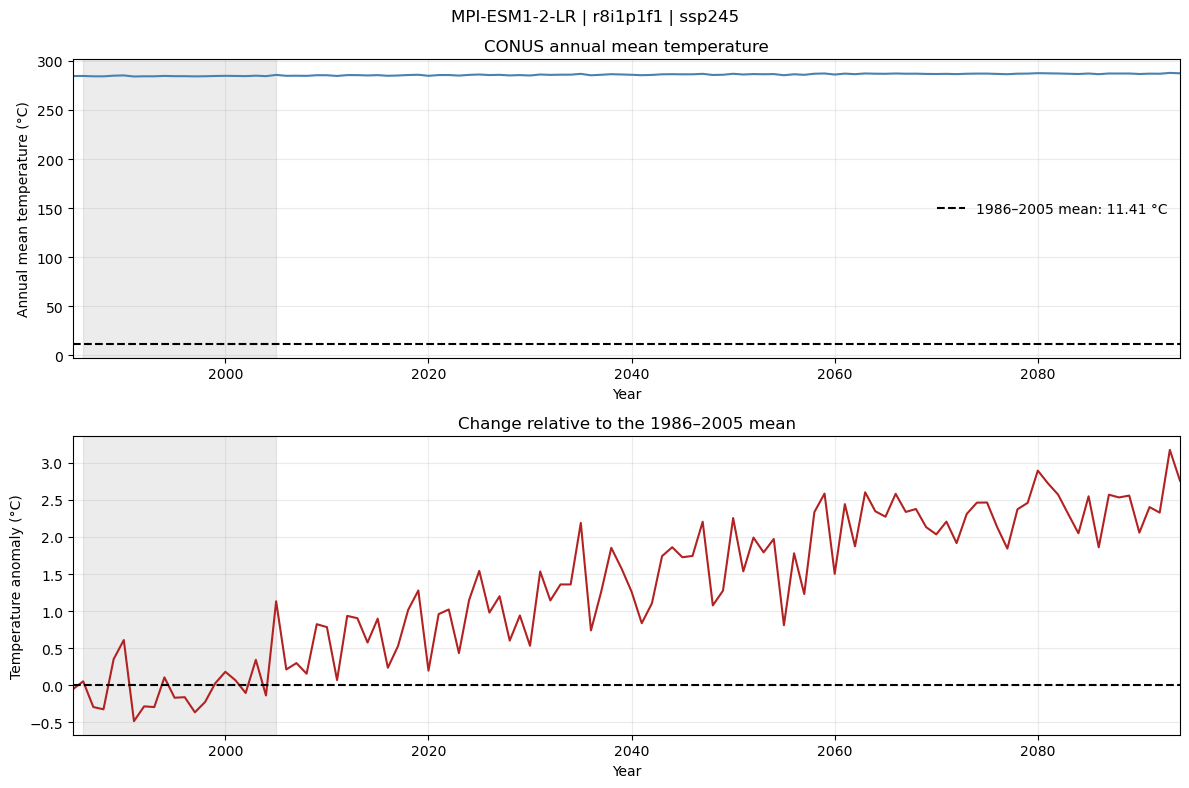

Selected file: Wobus_et_al_2021__MPI-ESM1-2-LR_r8i1p1f1_ssp245.nc


In [17]:
import random
import matplotlib.pyplot as plt
import xarray as xr

selected_file = random.choice(sorted(OUTPUT_ROOT.glob("*.nc")))

with xr.open_dataset(selected_file) as ds:
    years = ds["calendar_year"].values
    temperature = ds["conus_annual_mean_temperature"].values
    warming = ds["conus_warming_relative_to_1986_2005"].values
    baseline = ds["baseline_1986_2005_temperature"].item()
    title = " | ".join(
        str(ds.attrs.get(key, "Unknown"))
        for key in ("model", "member", "scenario")
    )

fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)

axes[0].plot(years, temperature, color="steelblue")
axes[0].axhline(
    baseline, color="black", linestyle="--",
    label=f"1986–2005 mean: {baseline:.2f} °C",
)
axes[0].set_ylabel("Annual mean temperature (°C)")
axes[0].set_title("CONUS annual mean temperature")
axes[0].legend(frameon=False)

axes[1].plot(years, warming, color="firebrick")
axes[1].axhline(0, color="black", linestyle="--")
axes[1].set_ylabel("Temperature anomaly (°C)")
axes[1].set_title("Change relative to the 1986–2005 mean")

for ax in axes:
    ax.axvspan(1986, 2005, color="gray", alpha=0.15)
    ax.set_xlabel("Year")
    ax.tick_params(axis="x", labelbottom=True)
    ax.set_xlim(years.min(), years.max())
    ax.grid(alpha=0.25)

fig.suptitle(title)
fig.tight_layout()
plt.show()

print("Selected file:", selected_file.name)